In [1]:
import pandas as pd
import sqlite3
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('retail_sales_dataset.csv')

conn = sqlite3.connect('retail_sales.db')

df.to_sql('sales', conn, if_exists='replace', index=False)

print("Database created successfully!")
print("Total Rows:", len(df))
print("Columns:", df.columns.tolist())

Saving retail_sales_dataset.csv to retail_sales_dataset.csv
Database created successfully!
Total Rows: 1000
Columns: ['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


Database Setup

In [2]:
import pandas as pd
import sqlite3
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re
import zipfile

from google.colab import files
from IPython.display import display

# Upload dataset
uploaded = files.upload()

filename = next(iter(uploaded))

# Read dataset
df = pd.read_csv(filename)

# Normalize column names
df.columns = [
    re.sub(r'[^a-z0-9]+', '_', col.lower()).strip('_')
    for col in df.columns
]

# Create database
conn = sqlite3.connect('retail_sales.db')

df.to_sql('sales', conn, if_exists='replace', index=False)

print("Database created successfully!")
print("Rows:", len(df))
print("Columns:", df.columns.tolist())

Saving retail_sales_dataset.csv to retail_sales_dataset (1).csv
Database created successfully!
Rows: 1000
Columns: ['transaction_id', 'date', 'customer_id', 'gender', 'age', 'product_category', 'quantity', 'price_per_unit', 'total_amount']


Data Inspection

In [3]:
# First five rows
display(df.head())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
display(df.describe(include='all'))

# Dataset shape
print("\nDataset Shape:", df.shape)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

,transaction_id,date,customer_id,gender,age,product_category,quantity,price_per_unit,total_amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   transaction_id    1000 non-null   int64 
 1   date              1000 non-null   object
 2   customer_id       1000 non-null   object
 3   gender            1000 non-null   object
 4   age               1000 non-null   int64 
 5   product_category  1000 non-null   object
 6   quantity          1000 non-null   int64 
 7   price_per_unit    1000 non-null   int64 
 8   total_amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


,transaction_id,date,customer_id,gender,age,product_category,quantity,price_per_unit,total_amount
count,1000.000000,1000,1000,1000,1000.00000,1000,1000.000000,1000.000000,1000.000000
unique,NaN,345,1000,2,NaN,3,NaN,NaN,NaN
top,NaN,2023-05-16,CUST001,Female,NaN,Clothing,NaN,NaN,NaN
freq,NaN,11,1,510,NaN,351,NaN,NaN,NaN
mean,500.500000,NaN,NaN,NaN,41.39200,NaN,2.514000,179.890000,456.000000
std,288.819436,NaN,NaN,NaN,13.68143,NaN,1.132734,189.681356,559.997632
min,1.000000,NaN,NaN,NaN,18.00000,NaN,1.000000,25.000000,25.000000
25%,250.750000,NaN,NaN,NaN,29.00000,NaN,1.000000,30.000000,60.000000
50%,500.500000,NaN,NaN,NaN,42.00000,NaN,3.000000,50.000000,135.000000
75%,750.250000,NaN,NaN,NaN,53.00000,NaN,4.000000,300.000000,900.000000



Dataset Shape: (1000, 9)

Missing Values:
transaction_id      0
date                0
customer_id         0
gender              0
age                 0
product_category    0
quantity            0
price_per_unit      0
total_amount        0
dtype: int64

Duplicate Records: 0


Data Cleaning

In [4]:
# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing values
df = df.dropna()

# Convert date column
if 'date' in df.columns:
    df['date'] = pd.to_datetime(
        df['date'], errors='coerce'
    ).dt.strftime('%Y-%m-%d')

# Convert numeric columns
numeric_columns = [
    'age', 'quantity', 'price_per_unit', 'total_amount'
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

df = df.dropna()

# Update database
df.to_sql('sales', conn, if_exists='replace', index=False)

print("Data cleaning completed!")
print("Remaining records:", len(df))
print("Missing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())

Data cleaning completed!
Remaining records: 1000
Missing values: 0
Duplicate records: 0


SQL Environment Setup

In [5]:
def run_query(query):
    result = pd.read_sql_query(query, conn)
    display(result)
    return result

print("SQL environment ready!")

SQL environment ready!


SQL Analysis – 10 Important Queries

In [6]:
q1 = """
SELECT *
FROM sales
LIMIT 10;
"""

result1 = run_query(q1)

,transaction_id,date,customer_id,gender,age,product_category,quantity,price_per_unit,total_amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
5,6,2023-04-25,CUST006,Female,45,Beauty,1,30,30
6,7,2023-03-13,CUST007,Male,46,Clothing,2,25,50
7,8,2023-02-22,CUST008,Male,30,Electronics,4,25,100
8,9,2023-12-13,CUST009,Male,63,Electronics,2,300,600
9,10,2023-10-07,CUST010,Female,52,Clothing,4,50,200


Query 1: View all records

In [7]:
q1 = """
SELECT *
FROM sales
LIMIT 10;
"""

result1 = run_query(q1)

,transaction_id,date,customer_id,gender,age,product_category,quantity,price_per_unit,total_amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
5,6,2023-04-25,CUST006,Female,45,Beauty,1,30,30
6,7,2023-03-13,CUST007,Male,46,Clothing,2,25,50
7,8,2023-02-22,CUST008,Male,30,Electronics,4,25,100
8,9,2023-12-13,CUST009,Male,63,Electronics,2,300,600
9,10,2023-10-07,CUST010,Female,52,Clothing,4,50,200


Query 2: Total Sales, Revenue and Customers

In [8]:
q2 = """
SELECT
    COUNT(*) AS total_transactions,
    SUM(quantity) AS total_items_sold,
    ROUND(SUM(total_amount), 2) AS total_revenue,
    COUNT(DISTINCT customer_id) AS total_customers,
    ROUND(AVG(total_amount), 2) AS average_transaction_value
FROM sales;
"""

result2 = run_query(q2)

,total_transactions,total_items_sold,total_revenue,total_customers,average_transaction_value
0,1000,2514,456000.0,1000,456.0


Query 3: Sales by Product Category

In [9]:
q3 = """
SELECT
    product_category,
    COUNT(*) AS total_transactions,
    SUM(quantity) AS total_quantity,
    ROUND(SUM(total_amount), 2) AS total_revenue
FROM sales
GROUP BY product_category
ORDER BY total_revenue DESC;
"""

result3 = run_query(q3)

,product_category,total_transactions,total_quantity,total_revenue
0,Electronics,342,849,156905.0
1,Clothing,351,894,155580.0
2,Beauty,307,771,143515.0


Query 4: Monthly Sales Trends

In [10]:
q4 = """
SELECT
    strftime('%Y-%m', date) AS sales_month,
    COUNT(*) AS transactions,
    ROUND(SUM(total_amount), 2) AS monthly_revenue
FROM sales
GROUP BY sales_month
ORDER BY sales_month;
"""

result4 = run_query(q4)

,sales_month,transactions,monthly_revenue
0,2023-01,76,35450.0
1,2023-02,85,44060.0
2,2023-03,73,28990.0
3,2023-04,86,33870.0
4,2023-05,105,53150.0
5,2023-06,77,36715.0
6,2023-07,72,35465.0
7,2023-08,94,36960.0
8,2023-09,65,23620.0
9,2023-10,96,46580.0


Query 5: Sales by Gender

In [11]:
q5 = """
SELECT
    gender,
    COUNT(*) AS transactions,
    ROUND(SUM(total_amount), 2) AS total_revenue,
    ROUND(AVG(total_amount), 2) AS average_spending
FROM sales
GROUP BY gender
ORDER BY total_revenue DESC;
"""

result5 = run_query(q5)

,gender,transactions,total_revenue,average_spending
0,Female,510,232840.0,456.55
1,Male,490,223160.0,455.43


Query 6: Age Group Analysis

In [12]:
q6 = """
SELECT
    CASE
        WHEN age < 20 THEN 'Under 20'
        WHEN age BETWEEN 20 AND 29 THEN '20-29'
        WHEN age BETWEEN 30 AND 39 THEN '30-39'
        WHEN age BETWEEN 40 AND 49 THEN '40-49'
        ELSE '50+'
    END AS age_group,
    COUNT(*) AS transactions,
    ROUND(SUM(total_amount), 2) AS total_revenue
FROM sales
GROUP BY age_group
ORDER BY total_revenue DESC;
"""

result6 = run_query(q6)

,age_group,transactions,total_revenue
0,50+,336,143155.0
1,20-29,209,97070.0
2,30-39,191,96325.0
3,40-49,222,93365.0
4,Under 20,42,26085.0


Query 7: Top 10 Customers by Spending

In [13]:
q7 = """
SELECT
    customer_id,
    COUNT(*) AS total_transactions,
    ROUND(SUM(total_amount), 2) AS total_spending
FROM sales
GROUP BY customer_id
ORDER BY total_spending DESC
LIMIT 10;
"""

result7 = run_query(q7)

,customer_id,total_transactions,total_spending
0,CUST970,1,2000.0
1,CUST946,1,2000.0
2,CUST927,1,2000.0
3,CUST875,1,2000.0
4,CUST832,1,2000.0
5,CUST808,1,2000.0
6,CUST789,1,2000.0
7,CUST773,1,2000.0
8,CUST743,1,2000.0
9,CUST742,1,2000.0


Query 8: Best-Selling Categories by Quantity

In [14]:
q8 = """
SELECT
    product_category,
    SUM(quantity) AS units_sold
FROM sales
GROUP BY product_category
ORDER BY units_sold DESC;
"""

result8 = run_query(q8)

,product_category,units_sold
0,Clothing,894
1,Electronics,849
2,Beauty,771


Query 9: Highest Revenue Transactions

In [15]:
q9 = """
SELECT
    transaction_id,
    customer_id,
    product_category,
    quantity,
    total_amount
FROM sales
ORDER BY total_amount DESC
LIMIT 10;
"""

result9 = run_query(q9)

,transaction_id,customer_id,product_category,quantity,total_amount
0,15,CUST015,Electronics,4,2000
1,65,CUST065,Electronics,4,2000
2,72,CUST072,Electronics,4,2000
3,74,CUST074,Beauty,4,2000
4,89,CUST089,Electronics,4,2000
5,93,CUST093,Beauty,4,2000
6,109,CUST109,Electronics,4,2000
7,118,CUST118,Electronics,4,2000
8,124,CUST124,Clothing,4,2000
9,139,CUST139,Beauty,4,2000


Query 10: Weekday Sales Analysis

In [16]:
q10 = """
SELECT
    CASE strftime('%w', date)
        WHEN '0' THEN 'Sunday'
        WHEN '1' THEN 'Monday'
        WHEN '2' THEN 'Tuesday'
        WHEN '3' THEN 'Wednesday'
        WHEN '4' THEN 'Thursday'
        WHEN '5' THEN 'Friday'
        WHEN '6' THEN 'Saturday'
    END AS weekday,
    COUNT(*) AS transactions,
    ROUND(SUM(total_amount), 2) AS revenue
FROM sales
GROUP BY strftime('%w', date)
ORDER BY strftime('%w', date);
"""

result10 = run_query(q10)

,weekday,transactions,revenue
0,Sunday,138,58600.0
1,Monday,146,70250.0
2,Tuesday,161,69440.0
3,Wednesday,139,58770.0
4,Thursday,123,53835.0
5,Friday,143,66290.0
6,Saturday,150,78815.0


Data Visualization

In [17]:
os.makedirs('project_outputs', exist_ok=True)

sns.set_theme(style="whitegrid")

Graph 1: Revenue by Product Category

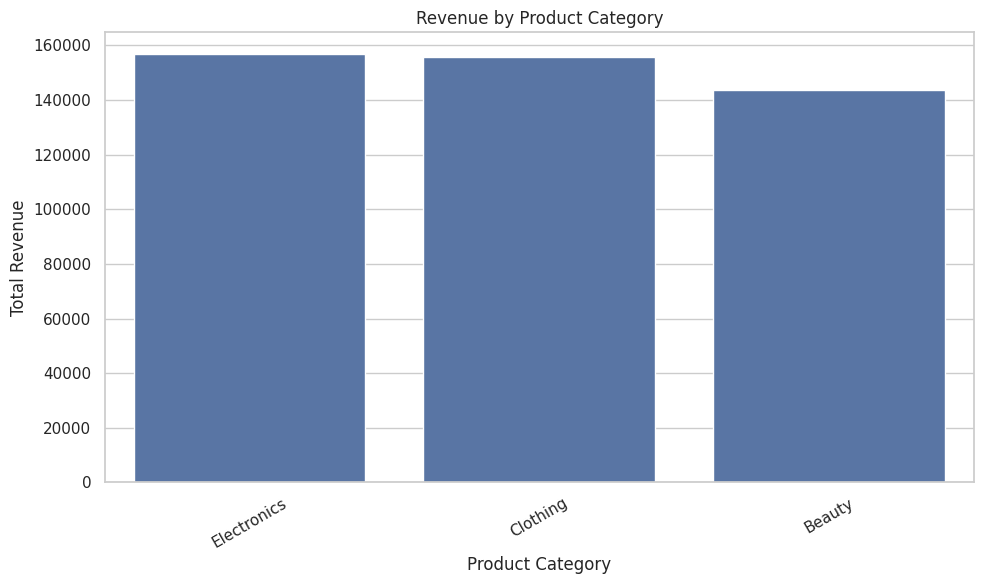

In [18]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=result3,
    x='product_category',
    y='total_revenue'
)

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    'project_outputs/category_revenue.png',
    dpi=300
)

plt.show()

Graph 2: Monthly Revenue Trend

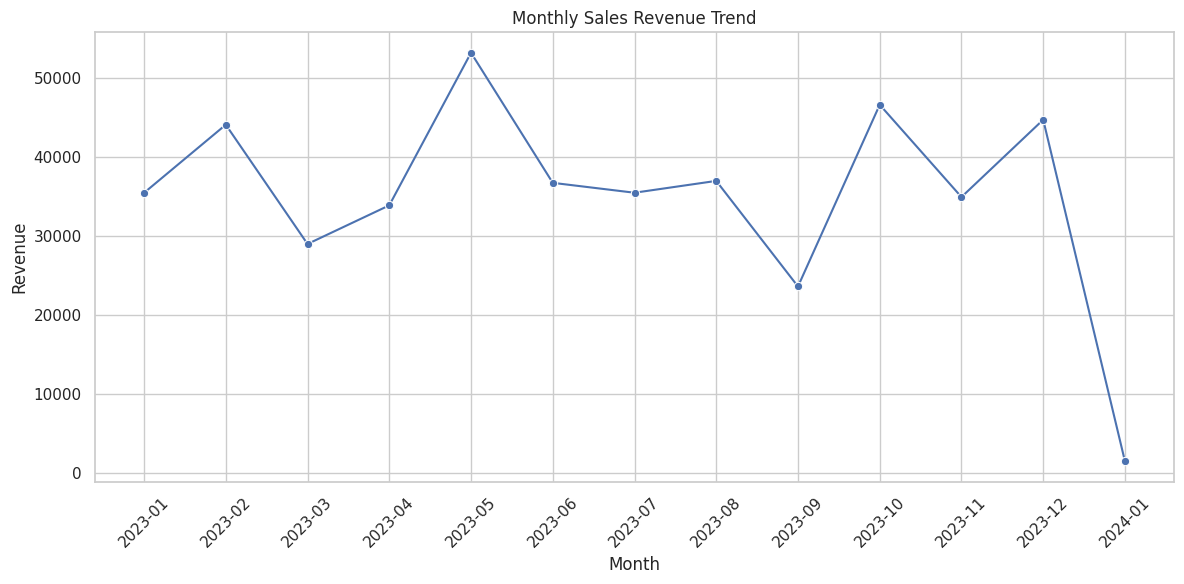

In [19]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=result4,
    x='sales_month',
    y='monthly_revenue',
    marker='o'
)

plt.title('Monthly Sales Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    'project_outputs/monthly_revenue.png',
    dpi=300
)

plt.show()

Graph 3: Sales by Gender

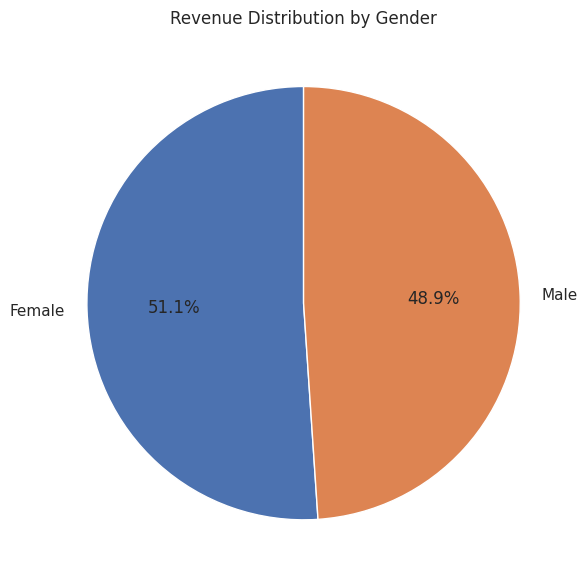

In [20]:
plt.figure(figsize=(8, 6))

plt.pie(
    result5['total_revenue'],
    labels=result5['gender'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Revenue Distribution by Gender')
plt.tight_layout()

plt.savefig(
    'project_outputs/gender_sales.png',
    dpi=300
)

plt.show()

Graph 4: Revenue by Age Group

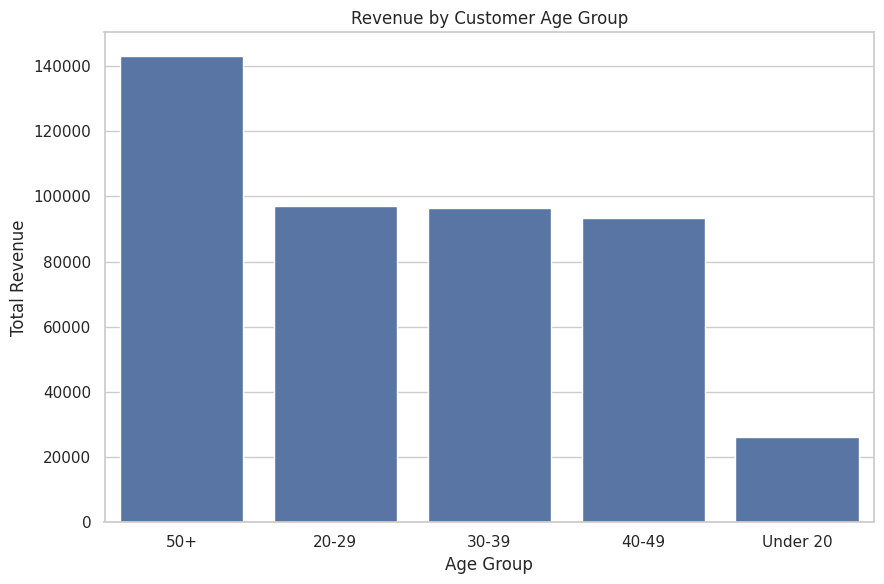

In [21]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=result6,
    x='age_group',
    y='total_revenue'
)

plt.title('Revenue by Customer Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Revenue')
plt.tight_layout()

plt.savefig(
    'project_outputs/age_group_revenue.png',
    dpi=300
)

plt.show()

Export SQL Reports as CSV

In [22]:
reports = {
    'overall_summary': result2,
    'category_analysis': result3,
    'monthly_sales': result4,
    'gender_analysis': result5,
    'age_group_analysis': result6,
    'top_customers': result7,
    'best_selling_categories': result8,
    'top_transactions': result9,
    'weekday_analysis': result10
}

for name, report in reports.items():
    report.to_csv(
        f'project_outputs/{name}.csv',
        index=False
    )

# Save cleaned dataset
df.to_csv(
    'project_outputs/cleaned_retail_sales.csv',
    index=False
)

print("All CSV reports exported successfully!")

All CSV reports exported successfully!


Generate Actual Business Insights

In [23]:
summary = result2.iloc[0]

print("=" * 45)
print("RETAIL SALES BUSINESS INSIGHTS")
print("=" * 45)

print("Total Transactions:",
      summary['total_transactions'])

print("Total Items Sold:",
      summary['total_items_sold'])

print("Total Revenue:",
      summary['total_revenue'])

print("Total Customers:",
      summary['total_customers'])

print("Average Transaction Value:",
      summary['average_transaction_value'])

print("\nHighest Revenue Category:")

display(result3.head(1))

print("\nHighest Revenue Month:")

display(
    result4.sort_values(
        'monthly_revenue',
        ascending=False
    ).head(1)
)

print("\nHighest Spending Customer:")

display(result7.head(1))

print("\nHighest Revenue Age Group:")

display(result6.head(1))

RETAIL SALES BUSINESS INSIGHTS
Total Transactions: 1000.0
Total Items Sold: 2514.0
Total Revenue: 456000.0
Total Customers: 1000.0
Average Transaction Value: 456.0

Highest Revenue Category:


,product_category,total_transactions,total_quantity,total_revenue
0,Electronics,342,849,156905.0



Highest Revenue Month:


,sales_month,transactions,monthly_revenue
4,2023-05,105,53150.0



Highest Spending Customer:


,customer_id,total_transactions,total_spending
0,CUST970,1,2000.0



Highest Revenue Age Group:


,age_group,transactions,total_revenue
0,50+,336,143155.0


Create Project Summary

In [24]:
summary_text = f"""
RETAIL SALES ANALYSIS USING SQL

PROJECT OVERVIEW
This project analyzes retail sales transactions
using SQL and Python.

DATASET
Total Records: {len(df)}
Total Columns: {len(df.columns)}

TOOLS
Python, Pandas, SQLite, SQL, Matplotlib, Seaborn

KEY METRICS
Total Transactions: {summary['total_transactions']}
Total Items Sold: {summary['total_items_sold']}
Total Revenue: {summary['total_revenue']}
Total Customers: {summary['total_customers']}
Average Transaction Value: {summary['average_transaction_value']}

TOP REVENUE CATEGORY
{result3.iloc[0]['product_category']}

TOP REVENUE MONTH
{result4.sort_values('monthly_revenue', ascending=False).iloc[0]['sales_month']}

ANALYSIS
- Overall sales performance
- Product category performance
- Monthly revenue trends
- Gender-based purchasing patterns
- Customer age group analysis
- Top customer spending
- Weekday sales patterns

CONCLUSION
The project demonstrates the use of SQL queries
and Python visualizations to analyze retail sales
data and extract business insights.

Author: Aysha Siddika
"""

with open(
    'project_outputs/project_summary.txt',
    'w'
) as file:
    file.write(summary_text)

print(summary_text)


RETAIL SALES ANALYSIS USING SQL

PROJECT OVERVIEW
This project analyzes retail sales transactions
using SQL and Python.

DATASET
Total Records: 1000
Total Columns: 9

TOOLS
Python, Pandas, SQLite, SQL, Matplotlib, Seaborn

KEY METRICS
Total Transactions: 1000.0
Total Items Sold: 2514.0
Total Revenue: 456000.0
Total Customers: 1000.0
Average Transaction Value: 456.0

TOP REVENUE CATEGORY
Electronics

TOP REVENUE MONTH
2023-05

ANALYSIS
- Overall sales performance
- Product category performance
- Monthly revenue trends
- Gender-based purchasing patterns
- Customer age group analysis
- Top customer spending
- Weekday sales patterns

CONCLUSION
The project demonstrates the use of SQL queries
and Python visualizations to analyze retail sales
data and extract business insights.

Author: Aysha Siddika



Create ZIP File

In [25]:
import shutil

# Save database changes
conn.commit()

# Close database connection
conn.close()

# Create ZIP
shutil.make_archive(
    'retail_sales_outputs',
    'zip',
    'project_outputs'
)

print("ZIP file created successfully!")

ZIP file created successfully!


In [26]:
from google.colab import files

# Download ZIP reports
files.download('retail_sales_outputs.zip')

# Download SQL database
files.download('retail_sales.db')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>